# Project 03 · Recognition memory across all sessions: true status vs reported judgment

Notebook 02 analysed one session (25 test trials), which cannot distinguish a modest effect from chance. This notebook asks two questions across **every session in [DANDI:000004](https://dandiarchive.org/dandiset/000004)** (Chandravadia et al., 2020, *Scientific Data*).

**Analysis plan, fixed on 25 October 2026 before any real data were analysed.**

**Q1 · Replication.** Does early post-stimulus spiking decode whether a recognition image is new or old better than chance, and better than pre-stimulus activity?

**Q2 · Reported vs true.** On trials where the patient answered wrongly, does neural activity follow what the patient *reported*, or the image's *true* status?

**Design**
- **Unit of inference: the patient.** Neurons differ between sessions, so decoders are fitted within each session. Generalization is assessed by replication across patients, not by one cross-patient decoder. Sessions from the same patient are averaged.
- **Features:** spike counts per neuron, 0.05–0.85 s after image onset. Control window: −0.85 to −0.05 s.
- **Model:** standardized counts + L2 logistic regression with balanced class weights, as in notebook 02. No tuning.
- **Q1 metric:** ROC AUC averaged over 5 contiguous, chronological folds within each session. Tests across patients: Wilcoxon signed-rank of AUC vs 0.5 (post and pre), and paired post vs pre.
- **Q2 metric:** a decoder trained only on *correct* trials (where report = truth) is applied to *error* trials. **Report agreement** = proportion of error trials where the decoder's label matches the patient's report. 0.5 = no information, below 0.5 = follows true status, above 0.5 = follows the report. Test across patients with ≥ 5 error trials: Wilcoxon vs 0.5, two-sided. Repeated with the pre-stimulus window as a control.
- **Exclusions:** trials with no valid response, or a response before 0.85 s, are excluded from Q2 so motor activity cannot enter the window. Sessions with fewer than 3 neurons or 20 usable trials are skipped and listed.
- **True status:** the stored `new_old_labels_recog` label, read as 1 = old, 0 = new, and checked against the images in every session (see the changes below).
- **Response coding:** 1–3 = "new" (confident → guess), 4–6 = "old" (guess → confident). TTL codes 31–36 are mapped to 1–6. **Sanity check:** median behavioural accuracy across sessions must exceed 0.5, or the notebook stops because the coding would be inverted.
- **Primary tests:** Q1 post-stimulus AUC vs 0.5, and Q2 post-stimulus agreement vs 0.5, each at α = .05. Everything else is secondary or descriptive.

**Changes to the plan, 25 October 2026**
1. *Label direction.* The plan read `new_old_labels_recog` as its description in the files says ("0 == Old Stimuli … 1 = New Stimuli"). The first run was stopped at session 9 of 87 because behaviour was below chance (68–76 "errors" per 100 trials). The images show the label is 1 = old: in sub-P10HMH it is 1 for all 50 recognition images shown during learning and 0 for the other 50.
2. *Which truth to use.* A complete run then took true status from the images (an image is old if the same file appears in the learning phase). It showed that 7 files contain only 50 of the 100 learning trials and one contains 97. In those 8 files, every disagreement with the stored label (21–24 trials in each 50-trial file, 1 in the 97-trial file) is an image the label calls old that is missing from the file's learning trials, which is what missing learning trials would produce. In the other 77 sessions the two definitions agree on every trial. The stored label is therefore the primary truth. Because this choice was made after the image-based run had been seen (Q2 agreement 0.527, p = .049), that run is reported as a sensitivity analysis, along with one that drops the 8 sessions.
3. *Exploratory category controls, added after the results were seen.* Neurons in the medial temporal lobe respond to visual category, which can distort both tests without any memory signal:
   - **Q2:** if patients call some categories "old" more often, a decoder trained on correct trials learns category, and agreement rises above 0.5. The pre-stimulus control cannot detect this. In simulations with that structure and no memory signal (40 simulated patients), agreement was 0.547 (p = .003).
   - **Q1:** if old and new images are balanced within each category, a category imbalance in the training folds forces the opposite imbalance in the test fold, so a decoder that uses category scores *below* chance. In simulations with category-tuned neurons and no memory signal, mean AUC was 0.462 with this balance and 0.508 without it.

   Both tests are therefore also compared with a null in which neural activity is shuffled among trials of the same image category. The shuffle keeps every category effect, including the stimulus set's category balance, and breaks any trial-level link with true status or the report. In those simulations the excess over this null was +0.005 for Q2 (p = .62) and +0.006 for Q1 (p = .51); the scripts are `test_03_category_confound.py` and `test_03_category_balance.py`.

Q1 AUCs do not depend on the label's direction: an L2 logistic decoder trained on reversed labels gives exactly mirrored predictions. The Q2 split into correct and error trials does depend on it.

**Limits:** the label is objective novelty, and the report is a judgment that includes decision and response processes. Error trials are relatively few, mix misses and false alarms, and are lower-confidence on average. Recordings come from patients with epilepsy, and the neurons sampled differ across sessions.

In [1]:
%pip -q install "dandi>=0.60" "remfile>=0.1" "pynwb>=3" "h5py>=3.9" "scikit-learn>=1.4" "scipy>=1.11" "pandas>=2" "matplotlib>=3.8"

In [2]:
from pathlib import Path
import io, json, time, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py, remfile
from pynwb import NWBHDF5IO
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

SEED = 42
DANDISET = '000004'
POST = (0.05, 0.85)       # seconds after image onset
PRE = (-0.85, -0.05)      # pre-stimulus control window
N_FOLDS = 5
MIN_UNITS, MIN_TRIALS, MIN_ERRORS = 3, 20, 5
TRUTH = 'stored_label'    # 'stored_label' (1 = old) or 'images' (old = shown in the learning phase)
MAX_SESSIONS = None       # e.g. 5 for a quick trial run
BASE = Path('/content') if Path('/content').exists() else Path('.')
CACHE = BASE / 'neurotech_data' / '000004_cache'
OUT = BASE / 'neurotech_results' / '03_across_sessions'
CACHE.mkdir(parents=True, exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', module='hdmf')
warnings.filterwarnings('ignore', module='pynwb')

In [3]:
# List every NWB file in the dandiset. Data are streamed later: only the trials and units tables are read.
from dandi.dandiapi import DandiAPIClient
with DandiAPIClient() as client:
    dandiset = client.get_dandiset(DANDISET)
    VERSION = dandiset.version_id
    assets = sorted((a for a in dandiset.get_assets() if a.path.endswith('.nwb')), key=lambda a: a.path)
    sources = [dict(path=a.path, asset_id=a.identifier, size_mb=round(a.size / 2**20, 1),
                    url=a.get_content_url(follow_redirects=1, strip_query=True)) for a in assets]
if MAX_SESSIONS:
    sources = sources[:MAX_SESSIONS]
print(f'DANDI:{DANDISET} version {VERSION}: {len(sources)} NWB files, '
      f'{len({s["path"].split("/")[0] for s in sources})} subjects')

DANDI:000004 version 0.220126.1852: 87 NWB files, 59 subjects


In [4]:
def read_session(src):
    """Return the trials table and one spike-time array per neuron. Results are cached locally."""
    trials_file = CACHE / f"{src['asset_id']}_trials_v2.csv"
    spikes_file = CACHE / f"{src['asset_id']}_spikes.npy"
    if trials_file.exists() and spikes_file.exists():
        return pd.read_csv(trials_file), list(np.load(spikes_file, allow_pickle=True))
    url = src['url']
    handle = remfile.File(url) if str(url).startswith('http') else url
    with h5py.File(handle, 'r') as h5, NWBHDF5IO(file=h5, mode='r', load_namespaces=True) as nwb_io:
        nwb = nwb_io.read()
        trials = nwb.trials.to_dataframe()
        ragged = nwb.units['spike_times']                  # index into one flat array of spike times
        ends = np.asarray(ragged.data[:])
        flat = np.asarray(ragged.target.data[:], dtype=float)
    spikes = [np.sort(x) for x in np.split(flat, ends[:-1])]
    keep = [c for c in ['stim_on_time', 'stim_phase', 'category_name', 'external_image_file',
                        'new_old_labels_recog', 'response_value', 'response_time'] if c in trials.columns]
    trials = trials[keep].reset_index(drop=True)
    trials.to_csv(trials_file, index=False)
    store = np.empty(len(spikes), dtype=object); store[:] = spikes
    np.save(spikes_file, store, allow_pickle=True)
    return trials, spikes


def recognition_trials(trials, truth=None):
    """Recognition-phase trials with true status (truth_new: 1 = new), the patient's report and response latency.

    truth='stored_label' reads new_old_labels_recog as 1 = old. Its description in the files says 0 = old, but the
    images show the opposite. truth='images' calls an image old if the same file appears in the learning phase."""
    truth = truth or TRUTH
    phase = trials['stim_phase'].astype(str).str.lower()
    learn = trials[phase.str.contains('learn')]
    t = trials[phase.str.contains('recog')].copy()
    col = lambda name: pd.to_numeric(t[name], errors='coerce') if name in t else pd.Series(np.nan, index=t.index)
    t['stored_label'] = col('new_old_labels_recog')
    if 'external_image_file' in trials and len(learn):
        t['old_by_image'] = t['external_image_file'].isin(set(learn['external_image_file'].dropna())).astype(int)
    else:
        t['old_by_image'] = np.nan
    t['truth_new'] = 1 - (t['stored_label'] if truth == 'stored_label' else t['old_by_image'])
    t['onset'] = col('stim_on_time')
    learning_first = (bool(pd.to_numeric(learn['stim_on_time'], errors='coerce').max() < t['onset'].min())
                      if len(learn) else False)
    r = col('response_value')
    r = r.where(r < 30, r - 30)                      # TTL codes 31–36 -> 1–6
    t['response'] = r.where(r.between(1, 6))
    t['report_new'] = (t['response'] <= 3).astype(float).where(t['response'].notna())
    t['latency'] = col('response_time') - t['onset']
    t = t[t['truth_new'].isin([0, 1]) & t['onset'].notna()].sort_values('onset').reset_index(drop=True)
    t.attrs.update(learning_first=learning_first, n_learning_trials=len(learn))
    return t


def counts(spikes, onsets, window):
    """Trials × neurons matrix of spike counts in [onset + window[0], onset + window[1])."""
    X = np.zeros((len(onsets), len(spikes)))
    for j, s in enumerate(spikes):
        X[:, j] = np.searchsorted(s, onsets + window[1]) - np.searchsorted(s, onsets + window[0])
    return X

In [5]:
def model():
    return Pipeline([('scale', StandardScaler()),
                     ('logit', LogisticRegression(max_iter=5000, class_weight='balanced'))])


def chrono_auc(X, y):
    """Mean ROC AUC over contiguous chronological folds (no shuffling)."""
    aucs = []
    for tr, te in KFold(N_FOLDS, shuffle=False).split(X):
        if len(np.unique(y[tr])) < 2 or len(np.unique(y[te])) < 2:
            continue
        p = model().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
        aucs.append(roc_auc_score(y[te], p))
    return float(np.mean(aucs)) if aucs else np.nan


def usable_for_q2(t):
    return t['report_new'].notna() & (t['latency'] >= POST[1])


def error_trial_predictions(X, t):
    """Train on correct trials (report = truth); predict error trials. Errors are never used in training."""
    usable = usable_for_q2(t)
    correct = (usable & (t['report_new'] == t['truth_new'])).to_numpy()
    error = (usable & (t['report_new'] != t['truth_new'])).to_numpy()
    if error.sum() == 0 or t.loc[correct, 'truth_new'].nunique() < 2:
        return None
    m = model().fit(X[correct], t.loc[correct, 'truth_new'].to_numpy().astype(int))
    p_new = m.predict_proba(X[error])[:, 1]
    e = t.loc[error, ['onset', 'truth_new', 'report_new', 'response']].copy()
    e['p_new'] = p_new
    e['agrees_with_report'] = ((p_new > 0.5).astype(float) == e['report_new']).astype(int)
    e['error_type'] = np.where(e['truth_new'] == 1, 'false alarm (new judged old)', 'miss (old judged new)')
    return e

In [6]:
def analyse_session(t, spikes):
    """Q1 AUCs and Q2 error-trial predictions for one session's recognition trials."""
    onsets = t['onset'].to_numpy()
    y = t['truth_new'].to_numpy().astype(int)
    X = {'post': counts(spikes, onsets, POST), 'pre': counts(spikes, onsets, PRE)}
    valid = t['report_new'].notna()
    n_correct = int((t.loc[valid, 'report_new'] == t.loc[valid, 'truth_new']).sum())
    row = dict(n_units=len(spikes), n_trials=len(t), n_valid_responses=int(valid.sum()),
               behaviour_accuracy=n_correct / valid.sum() if valid.any() else np.nan,
               behaviour_p=stats.binomtest(n_correct, int(valid.sum()), alternative='greater').pvalue if valid.any() else np.nan,
               n_q2_errors=int((usable_for_q2(t) & (t['report_new'] != t['truth_new'])).sum()),
               auc_post=chrono_auc(X['post'], y), auc_pre=chrono_auc(X['pre'], y))
    frames = []
    for window in ('post', 'pre'):
        e = error_trial_predictions(X[window], t)
        if e is not None:
            e['window'] = window
            frames.append(e)
    return row, frames


def run_all(truth=None, verbose=False):
    """Analyse every listed session. Returns session results, error-trial predictions and skipped sessions."""
    rows, frames, skipped = [], [], []
    start = time.time()
    for k, src in enumerate(sources, 1):
        patient = src['path'].split('/')[0].replace('sub-', '')
        try:
            trials, spikes = read_session(src)
            t = recognition_trials(trials, truth)
            if len(spikes) < MIN_UNITS:
                raise ValueError(f'only {len(spikes)} neurons')
            if t['truth_new'].nunique() < 2 or len(t) < MIN_TRIALS:
                raise ValueError(f'{len(t)} usable recognition trials')
            result, session_frames = analyse_session(t, spikes)
            row = dict(session=src['path'], patient=patient, n_learning_trials=t.attrs['n_learning_trials'],
                       stored_label_marks_old=float((t['stored_label'] == t['old_by_image']).mean()),
                       learning_first=t.attrs['learning_first'], median_latency=float(t['latency'].median()), **result)
            for e in session_frames:
                e['session'], e['patient'] = src['path'], patient
                frames.append(e)
            rows.append(row)
            if verbose:
                print(f"[{k}/{len(sources)}] {src['path']}: {len(spikes)} neurons, AUC post {row['auc_post']:.2f} "
                      f"/ pre {row['auc_pre']:.2f}, {row['n_q2_errors']} error trials ({time.time() - start:.0f} s)")
        except Exception as exc:
            skipped.append(dict(session=src['path'], reason=f'{type(exc).__name__}: {exc}'))
            if verbose:
                print(f"[{k}/{len(sources)}] {src['path']}: SKIPPED ({type(exc).__name__}: {str(exc)[:120]})")
    errors = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    return pd.DataFrame(rows), errors, pd.DataFrame(skipped, columns=['session', 'reason'])


sessions, errors, skipped = run_all(verbose=True)
sessions.to_csv(OUT / 'session_results.csv', index=False)
errors.to_csv(OUT / 'error_trial_predictions.csv', index=False)
skipped.to_csv(OUT / 'skipped_sessions.csv', index=False)
print(f'\nAnalysed {len(sessions)} sessions from {sessions.patient.nunique()} patients; skipped {len(skipped)}.')

[1/87] sub-P10HMH/sub-P10HMH_ses-20060901_ecephys+image.nwb: 38 neurons, AUC post 0.62 / pre 0.31, 40 error trials (3 s)
[2/87] sub-P11HMH/sub-P11HMH_ses-20061101_ecephys+image.nwb: 25 neurons, AUC post 0.51 / pre 0.39, 27 error trials (5 s)
[3/87] sub-P14HMH/sub-P14HMH_ses-20070601_obj-1t8wrd5_ecephys+image.nwb: 23 neurons, AUC post 0.36 / pre 0.55, 32 error trials (7 s)
[4/87] sub-P14HMH/sub-P14HMH_ses-20070601_obj-7studd_ecephys+image.nwb: 33 neurons, AUC post 0.56 / pre 0.55, 29 error trials (9 s)
[5/87] sub-P15HMH/sub-P15HMH_ses-20070901_obj-a5xz9n_ecephys+image.nwb: 14 neurons, AUC post 0.48 / pre 0.44, 45 error trials (11 s)
[6/87] sub-P15HMH/sub-P15HMH_ses-20070901_obj-bdd49u_ecephys+image.nwb: 20 neurons, AUC post 0.64 / pre 0.55, 44 error trials (12 s)
[7/87] sub-P16HMH/sub-P16HMH_ses-20071001_obj-12ambkj_ecephys+image.nwb: 18 neurons, AUC post 0.48 / pre 0.42, 24 error trials (15 s)
[8/87] sub-P16HMH/sub-P16HMH_ses-20071001_obj-1jfnx96_ecephys+image.nwb: 21 neurons, AUC post

In [7]:
# Checks on the coding before any test is run
median_accuracy = sessions['behaviour_accuracy'].median()
print(f'Behavioural accuracy: median {median_accuracy:.3f}, range {sessions.behaviour_accuracy.min():.2f}-{sessions.behaviour_accuracy.max():.2f}; '
      f"{(sessions.behaviour_p >= .05).sum()} sessions not above chance (one-sided binomial p >= .05)")
print('Stored label agrees with the images (share of trials -> sessions):',
      sessions['stored_label_marks_old'].round(2).value_counts().sort_index().to_dict())
print('Learning trials in file -> sessions:', sessions['n_learning_trials'].value_counts().sort_index().to_dict())
print('Sessions where the images and the stored label disagree:')
print(sessions.loc[sessions.stored_label_marks_old < 1, ['session', 'n_learning_trials', 'stored_label_marks_old', 'behaviour_accuracy']].to_string())
print('Sessions where learning did not come before the test:', int((sessions['learning_first'] != True).sum()))
print(f"Median response latency (s): {sessions['median_latency'].median():.2f}")
print('Response codes seen:', sorted(pd.concat([recognition_trials(read_session(s)[0])['response'] for s in sources[:3]]).dropna().unique()))
assert median_accuracy > 0.5, 'Behaviour is below chance: the response coding is probably inverted. Stop and check.'


Behavioural accuracy: median 0.730, range 0.48-0.88; 7 sessions not above chance (one-sided binomial p >= .05)
Stored label agrees with the images (share of trials -> sessions): {0.76: 4, 0.79: 3, 0.99: 1, 1.0: 77}
Learning trials in file -> sessions: {50: 7, 97: 1, 100: 77}
Sessions where the images and the stored label disagree:
                                                             session  n_learning_trials  stored_label_marks_old  behaviour_accuracy
3    sub-P14HMH/sub-P14HMH_ses-20070601_obj-7studd_ecephys+image.nwb                 50                    0.79                0.71
4    sub-P15HMH/sub-P15HMH_ses-20070901_obj-a5xz9n_ecephys+image.nwb                 50                    0.76                0.55
5    sub-P15HMH/sub-P15HMH_ses-20070901_obj-bdd49u_ecephys+image.nwb                 50                    0.79                0.56
6   sub-P16HMH/sub-P16HMH_ses-20071001_obj-12ambkj_ecephys+image.nwb                 50                    0.76                0.76
9      

In [8]:
def wilcoxon_p(x, mu=0.5):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    return float(stats.wilcoxon(x - mu).pvalue) if len(x) >= 5 else np.nan


def bootstrap_ci(x, n=5000):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    means = np.random.default_rng(SEED).choice(x, (n, len(x))).mean(1)
    return np.quantile(means, [.025, .975]).round(3).tolist()


def summarise(sessions, errors):
    """Patient-level Q1 and Q2 statistics."""
    patients = sessions.groupby('patient')[['auc_post', 'auc_pre', 'behaviour_accuracy', 'n_units']].mean()
    q1 = dict(n_sessions=len(sessions), n_patients=len(patients),
              auc_post_mean=round(patients.auc_post.mean(), 3), auc_post_ci=bootstrap_ci(patients.auc_post),
              p_post_vs_chance=wilcoxon_p(patients.auc_post),
              auc_pre_mean=round(patients.auc_pre.mean(), 3), auc_pre_ci=bootstrap_ci(patients.auc_pre),
              p_pre_vs_chance=wilcoxon_p(patients.auc_pre),
              p_post_vs_pre=float(stats.wilcoxon(patients.auc_post - patients.auc_pre).pvalue),
              share_of_patients_post_above_half=round(float((patients.auc_post > .5).mean()), 3))
    q2, per_patient = {}, {}
    for window in ('post', 'pre'):
        e = errors[errors.window == window]
        per = e.groupby('patient').agg(n_errors=('agrees_with_report', 'size'),
                                       agreement=('agrees_with_report', 'mean'))
        per = per[per.n_errors >= MIN_ERRORS]
        per_patient[window] = per
        q2[window] = dict(n_patients=len(per), n_error_trials=int(per.n_errors.sum()),
                          agreement_mean=round(per.agreement.mean(), 3), agreement_ci=bootstrap_ci(per.agreement),
                          p_vs_half=wilcoxon_p(per.agreement))
    by_error_type = (errors[errors.window == 'post'].groupby('error_type')['agrees_with_report']
                     .agg(trials='size', agreement='mean').round(3))
    return q1, q2, patients, per_patient, by_error_type


q1, q2, patients, per_patient, by_error_type = summarise(sessions, errors)
patients.to_csv(OUT / 'patient_results.csv')
for window, per in per_patient.items():
    per.to_csv(OUT / f'patient_report_agreement_{window}.csv')
print('Q1 (primary: post vs chance):', json.dumps(q1, indent=1))
print('\nQ2 (primary: post agreement vs 0.5):', json.dumps(q2, indent=1))
print('\nQ2 by error type (post window, descriptive):'); display(by_error_type)

Q1 (primary: post vs chance): {
 "n_sessions": 85,
 "n_patients": 58,
 "auc_post_mean": 0.506,
 "auc_post_ci": [
  0.491,
  0.521
 ],
 "p_post_vs_chance": 0.22268489540586955,
 "auc_pre_mean": 0.506,
 "auc_pre_ci": [
  0.487,
  0.525
 ],
 "p_pre_vs_chance": 0.5798677669581713,
 "p_post_vs_pre": 0.7188327892407934,
 "share_of_patients_post_above_half": 0.569
}

Q2 (primary: post agreement vs 0.5): {
 "post": {
  "n_patients": 58,
  "n_error_trials": 2444,
  "agreement_mean": 0.531,
  "agreement_ci": [
   0.505,
   0.555
  ],
  "p_vs_half": 0.030317932617841076
 },
 "pre": {
  "n_patients": 58,
  "n_error_trials": 2444,
  "agreement_mean": 0.505,
  "agreement_ci": [
   0.482,
   0.527
  ],
  "p_vs_half": 0.5211902335760591
 }
}

Q2 by error type (post window, descriptive):


,trials,agreement
error_type,,
false alarm (new judged old),1149,0.546
miss (old judged new),1295,0.536


In [9]:
# Sensitivity analyses: secondary, added after the primary results were seen (see "Changes to the plan")
incomplete = set(sessions.loc[sessions.n_learning_trials < 100, 'session'])   # files missing part of the learning phase
weak = set(sessions.loc[sessions.behaviour_p >= .05, 'session'])
image_sessions, image_errors, _ = run_all(truth='images')
variants = {
    'Primary: stored label (1 = old)': (sessions, errors),
    'Truth from images': (image_sessions, image_errors),
    'Primary, without the incomplete-learning files': (sessions[~sessions.session.isin(incomplete)],
                                                        errors[~errors.session.isin(incomplete)]),
    'Primary, without sessions where behaviour is not above chance': (sessions[~sessions.session.isin(weak)],
                                                                       errors[~errors.session.isin(weak)]),
}
rows = []
for name, (s_, e_) in variants.items():
    a, b, *_ = summarise(s_, e_)
    rows.append({'analysis': name, 'patients': a['n_patients'], 'Q1 AUC post': a['auc_post_mean'], 'Q1 p': a['p_post_vs_chance'],
                 'Q2 patients': b['post']['n_patients'], 'Q2 agreement post': b['post']['agreement_mean'],
                 'Q2 95% CI': b['post']['agreement_ci'], 'Q2 p': b['post']['p_vs_half'],
                 'Q2 agreement pre': b['pre']['agreement_mean'], 'Q2 pre p': b['pre']['p_vs_half']})
sensitivity = pd.DataFrame(rows).set_index('analysis')
sensitivity.to_csv(OUT / 'sensitivity_analyses.csv')
print(f'{len(incomplete)} incomplete-learning files; {len(weak)} sessions with behaviour not above chance (binomial p >= .05)')
display(sensitivity.round(3))

8 incomplete-learning files; 7 sessions with behaviour not above chance (binomial p >= .05)


,patients,Q1 AUC post,Q1 p,Q2 patients,Q2 agreement post,Q2 95% CI,Q2 p,Q2 agreement pre,Q2 pre p
analysis,,,,,,,,,
Primary: stored label (1 = old),58,0.506,0.223,58,0.531,"[0.505, 0.555]",0.030,0.505,0.521
Truth from images,58,0.503,0.518,58,0.527,"[0.502, 0.551]",0.049,0.500,0.922
"Primary, without the incomplete-learning files",56,0.500,0.443,56,0.531,"[0.505, 0.558]",0.040,0.497,0.950
"Primary, without sessions where behaviour is not above chance",53,0.504,0.428,53,0.525,"[0.5, 0.551]",0.097,0.503,0.629


In [10]:
# Category controls: exploratory, added after the results were seen ("Changes to the plan", item 3)
# Null: shuffle neural activity among trials of the same image category, then rerun the same procedure.
# This keeps every category effect (category-selective neurons, category-dependent response bias, the stimulus
# set's category balance) and breaks any trial-level link between neural activity and true status or the report.
N_PERM_Q1, N_PERM_Q2 = 50, 100


def shuffle_within_category(cat, rng):
    idx = np.arange(len(cat))
    for c in np.unique(cat):
        members = np.flatnonzero(cat == c)
        idx[members] = rng.permutation(members)
    return idx


rng = np.random.default_rng(SEED)
analysed, rows, start = set(sessions.session), [], time.time()
for src in sources:
    if src['path'] not in analysed:
        continue
    trials, spikes = read_session(src)
    t = recognition_trials(trials)
    cat, y = t['category_name'].astype(str).to_numpy(), t['truth_new'].to_numpy().astype(int)
    X = counts(spikes, t['onset'].to_numpy(), POST)
    row = dict(session=src['path'], patient=src['path'].split('/')[0].replace('sub-', ''),
               category_balanced=bool((pd.crosstab(cat, y).nunique(axis=1) == 1).all()),   # old = new in every category
               auc_observed=chrono_auc(X, y),
               auc_null=np.nanmean([chrono_auc(X[shuffle_within_category(cat, rng)], y) for _ in range(N_PERM_Q1)]))
    e = error_trial_predictions(X, t)
    if e is not None:
        nulls = [error_trial_predictions(X[shuffle_within_category(cat, rng)], t) for _ in range(N_PERM_Q2)]
        row.update(n_errors=len(e), agreement_observed=e['agrees_with_report'].mean(),
                   agreement_null=np.mean([n['agrees_with_report'].mean() for n in nulls if n is not None]))
    rows.append(row)
by_session = pd.DataFrame(rows)
by_session.to_csv(OUT / 'category_null_by_session.csv', index=False)

# Patient level, pooled as in the primary tests (Q1: mean of sessions; Q2: weighted by error trials)
q1_null = by_session.groupby('patient')[['auc_observed', 'auc_null']].mean()
q1_null['excess'] = q1_null.auc_observed - q1_null.auc_null
q2_rows = by_session.dropna(subset=['n_errors'])
pooled = (q2_rows.assign(obs_x_n=q2_rows.agreement_observed * q2_rows.n_errors,
                         null_x_n=q2_rows.agreement_null * q2_rows.n_errors)
          .groupby('patient')[['n_errors', 'obs_x_n', 'null_x_n']].sum())
q2_null = pd.DataFrame(dict(n_errors=pooled.n_errors, observed=pooled.obs_x_n / pooled.n_errors,
                            null=pooled.null_x_n / pooled.n_errors))
q2_null = q2_null[q2_null.n_errors >= MIN_ERRORS]
q2_null['excess'] = q2_null.observed - q2_null.null


def describe(x, mu, test):
    return dict(n_patients=len(x), mean=round(float(np.mean(x)), 3), ci=bootstrap_ci(x), p=wilcoxon_p(x, mu), test=test)


category_control = pd.DataFrame({
    'Q1 AUC, observed': describe(q1_null.auc_observed, .5, 'vs 0.5'),
    'Q1 AUC, within-category null': describe(q1_null.auc_null, .5, 'vs 0.5'),
    'Q1 excess over the null': describe(q1_null.excess, 0, 'vs 0'),
    'Q2 agreement, observed': describe(q2_null.observed, .5, 'vs 0.5'),
    'Q2 agreement, within-category null': describe(q2_null.null, .5, 'vs 0.5'),
    'Q2 excess over the null': describe(q2_null.excess, 0, 'vs 0'),
}).T
category_control.to_csv(OUT / 'category_control.csv')
print(f'Old and new balanced within every image category in {by_session.category_balanced.sum()} of {len(by_session)} sessions')
print(f'{N_PERM_Q1} shuffles per session for Q1, {N_PERM_Q2} for Q2 ({time.time() - start:.0f} s)')
display(category_control)

Old and new balanced within every image category in 85 of 85 sessions
50 shuffles per session for Q1, 100 for Q2 (326 s)


,n_patients,mean,ci,p,test
"Q1 AUC, observed",58,0.506,"[0.491, 0.521]",0.222685,vs 0.5
"Q1 AUC, within-category null",58,0.495,"[0.492, 0.498]",0.002314,vs 0.5
Q1 excess over the null,58,0.011,"[-0.004, 0.026]",0.047043,vs 0
"Q2 agreement, observed",58,0.531,"[0.505, 0.555]",0.030318,vs 0.5
"Q2 agreement, within-category null",58,0.525,"[0.516, 0.534]",0.0,vs 0.5
Q2 excess over the null,58,0.006,"[-0.017, 0.029]",0.701537,vs 0


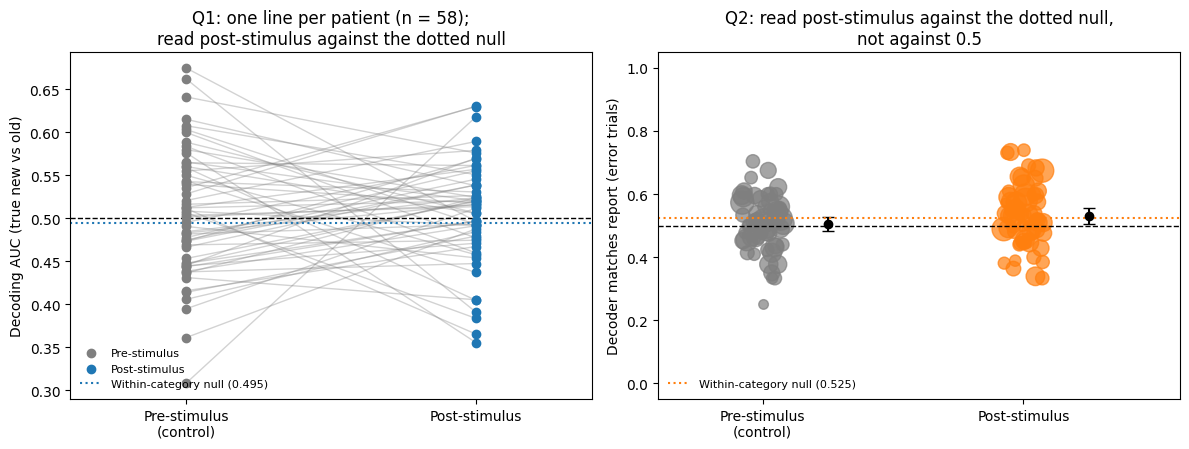

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
for _, r in patients.iterrows():
    ax.plot([0, 1], [r.auc_pre, r.auc_post], color='grey', alpha=.35, lw=1)
ax.scatter(np.zeros(len(patients)), patients.auc_pre, color='tab:grey', zorder=3, label='Pre-stimulus')
ax.scatter(np.ones(len(patients)), patients.auc_post, color='tab:blue', zorder=3, label='Post-stimulus')
ax.axhline(.5, ls='--', color='black', lw=1)
q1_line = category_control.loc['Q1 AUC, within-category null', 'mean']
ax.axhline(q1_line, ls=':', color='tab:blue', lw=1.5, label=f'Within-category null ({q1_line:.3f})')
ax.legend(loc='lower left', fontsize=8, frameon=False)
ax.set(xticks=[0, 1], xticklabels=['Pre-stimulus\n(control)', 'Post-stimulus'], xlim=(-.4, 1.4),
       ylabel='Decoding AUC (true new vs old)', title=f'Q1: one line per patient (n = {len(patients)});\nread post-stimulus against the dotted null')
ax = axes[1]
for i, (window, colour) in enumerate((('pre', 'tab:grey'), ('post', 'tab:orange'))):
    per = per_patient[window]
    ax.scatter(np.full(len(per), i) + np.random.default_rng(i).uniform(-.08, .08, len(per)), per.agreement,
               s=12 + 3 * per.n_errors, color=colour, alpha=.7)
    ax.errorbar(i + .25, per.agreement.mean(), yerr=np.abs(np.array(q2[window]['agreement_ci']) - per.agreement.mean())[:, None],
                fmt='o', color='black', capsize=4)
ax.axhline(.5, ls='--', color='black', lw=1)
null = category_control.loc['Q2 agreement, within-category null', 'mean']
ax.axhline(null, ls=':', color='tab:orange', lw=1.5, label=f'Within-category null ({null:.3f})')
ax.legend(loc='lower left', fontsize=8, frameon=False)
ax.set(xticks=[0, 1], xticklabels=['Pre-stimulus\n(control)', 'Post-stimulus'], xlim=(-.4, 1.6), ylim=(-.05, 1.05),
       ylabel='Decoder matches report (error trials)',
       title='Q2: read post-stimulus against the dotted null,\nnot against 0.5')
fig.tight_layout(); fig.savefig(OUT / 'across_sessions_summary.png', dpi=170); plt.show()

In [12]:
settings = dict(dandiset=DANDISET, version=VERSION, n_files_listed=len(sources), post_window=POST, pre_window=PRE,
                n_folds=N_FOLDS, min_units=MIN_UNITS, min_trials=MIN_TRIALS, min_errors=MIN_ERRORS,
                truth=TRUTH, q1=q1, q2=q2, sensitivity=sensitivity.reset_index().to_dict('records'),
                category_control=category_control.reset_index().to_dict('records'),
                python=platform.python_version(),
                packages={p: __import__(p).__version__ for p in ['numpy', 'pandas', 'sklearn', 'scipy', 'pynwb', 'h5py']})
(OUT / 'settings_and_results.json').write_text(json.dumps(settings, indent=2, default=float))
import shutil
archive = shutil.make_archive(str(OUT), 'zip', root_dir=str(OUT))
print('Saved:', *sorted(p.name for p in OUT.iterdir()), sep='\n - ')
print('Archive (download from the Files panel):', archive)

Saved:
 - across_sessions_summary.png
 - category_control.csv
 - category_null_by_session.csv
 - error_trial_predictions.csv
 - patient_report_agreement_post.csv
 - patient_report_agreement_pre.csv
 - patient_results.csv
 - sensitivity_analyses.csv
 - session_results.csv
 - settings_and_results.json
 - skipped_sessions.csv
Archive (download from the Files panel): /content/neurotech_results/03_across_sessions.zip


## Reading the results

- **Q1** asks whether new-vs-old information is present at all, replicated across patients. A post-stimulus AUC above chance that is also clearly above the pre-stimulus control supports stimulus-evoked information. A pre-stimulus AUC above chance points to drift or trial-order effects.
- **Q2** is the substantive question. Agreement **above 0.5** means that on errors the population activity looks like the patient's judgment rather than the true status. **Below 0.5** means it still tracks the truth: information the patient did not use. **Near 0.5** means error-trial activity carries no usable information either way, which is also what low-confidence errors would produce.
- A decoder trained on correct trials learns whatever separates new from old *when report and truth agree*. Its behaviour on errors shows which of the two that signal aligns with; it does not identify a mechanism.
- Category can move both tests without any memory signal. Agreement rises above 0.5 if patients' "old" responses depend on image category and neurons respond to category. AUC falls below 0.5 if old and new are balanced within each category. Read both tests against the within-category null.
- Errors are few per patient. Read the patient-level spread and the confidence interval, not just the p-value.